In [1]:
import sys
from pathlib import Path
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
DATA_DIR = Path('/content/drive/MyDrive/DeepMinds')   # shared folder: holds project_utils.py + torch_models.py
sys.path.append(str(DATA_DIR))
FIG_DIR = DATA_DIR / 'figures'; FIG_DIR.mkdir(exist_ok=True)
LOG = DATA_DIR / 'results_log.csv'

Mounted at /content/drive


In [2]:
#load everything
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from project_utils import COLORS

final = pd.read_csv(DATA_DIR / 'final_test_results.csv')
preds = pd.read_csv(DATA_DIR / 'final_test_predictions.csv')
log = pd.read_csv(LOG)
MODELS = ['Logistic Regression', 'Random Forest', 'MLP', 'Char-CNN']


def clean(ax):
    ax.grid(axis='y', color='#e1e0d9', lw=0.8); ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)


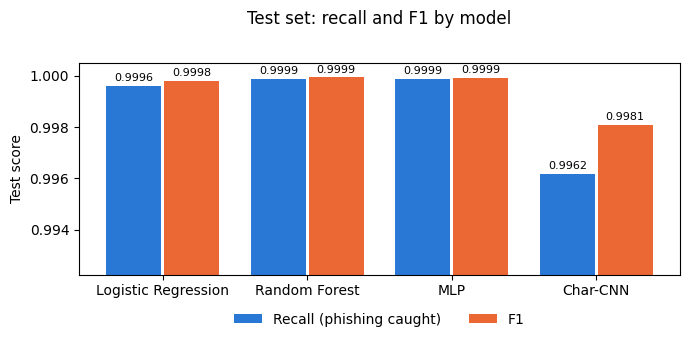

In [8]:
#headline figure: test recall and F1 per model (zoomed y-axis because every score is close to 1)
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(MODELS)); w = 0.38
f = final.set_index('Model').loc[MODELS]
b1 = ax.bar(x - w / 2 - 0.01, f['Recall'], w, color='#2a78d6', label='Recall (phishing caught)')
b2 = ax.bar(x + w / 2 + 0.01, f['F1'], w, color='#eb6834', label='F1')
ax.bar_label(b1, fmt='%.4f', fontsize=8, padding=2); ax.bar_label(b2, fmt='%.4f', fontsize=8, padding=2)
lo = min(f['Recall'].min(), f['F1'].min())
ax.set_ylim(max(0, lo - (1 - lo) * 0.5 - 0.002), 1.0005)
ax.set_xticks(x, MODELS); ax.set_ylabel('Test score'); ax.set_title('Test set: recall and F1 by model', pad=28)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
fig.tight_layout(); fig.savefig(FIG_DIR / 'final_recall_f1.png', dpi=200); plt.show()

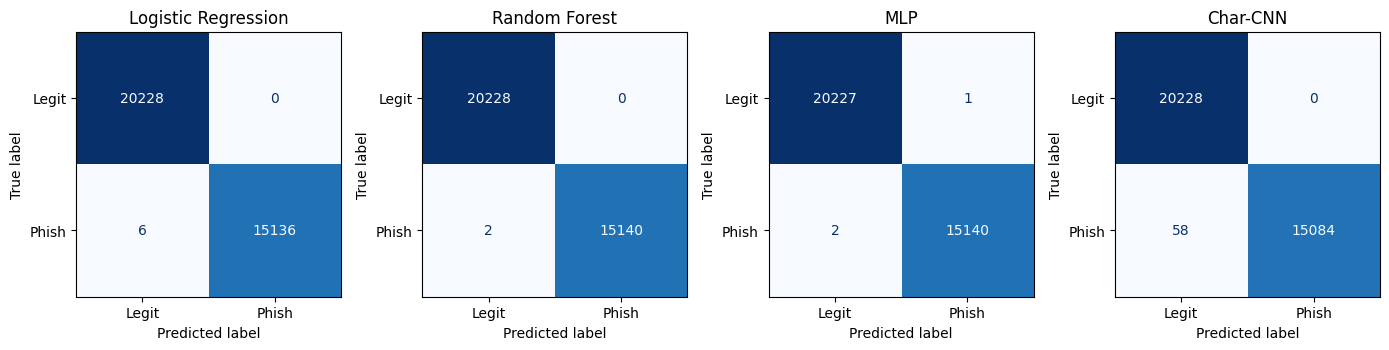

In [4]:
#confusion matrices side by side
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, name in zip(axes, MODELS):
    cm = confusion_matrix(preds['label'], (preds[name] >= 0.5).astype(int), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['Legit', 'Phish']).plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title(name)
fig.tight_layout(); fig.savefig(FIG_DIR / 'final_confusion_matrices.png', dpi=200); plt.show()


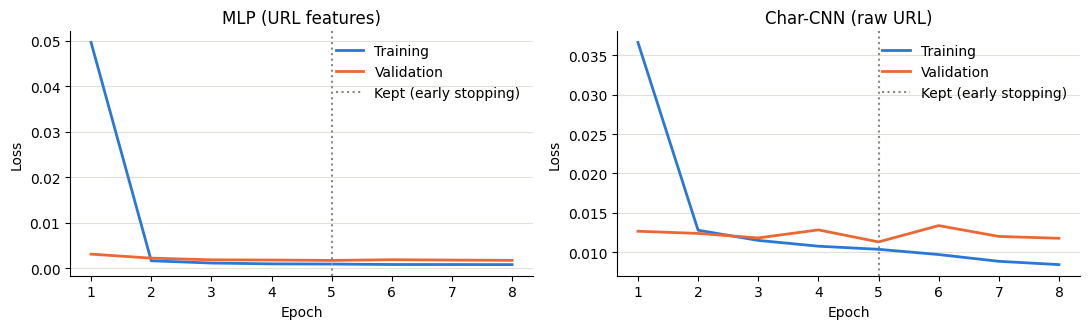

In [5]:
#learning curves: MLP and CNN
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=False)
for ax, (file, title) in zip(axes, [('history_mlp_url.json', 'MLP (URL features)'), ('history_cnn.json', 'Char-CNN (raw URL)')]):
    h = json.load(open(DATA_DIR / file))
    e = range(1, len(h['loss']) + 1)
    ax.plot(e, h['loss'], lw=2, color='#2a78d6', label='Training')
    ax.plot(e, h['val_loss'], lw=2, color='#eb6834', label='Validation')
    ax.axvline(h['best_epoch'], color='#888888', ls=':', label='Kept (early stopping)')
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.set_ylabel('Loss'); ax.legend(frameon=False); clean(ax)
fig.tight_layout(); fig.savefig(FIG_DIR / 'final_learning_curves.png', dpi=200); plt.show()

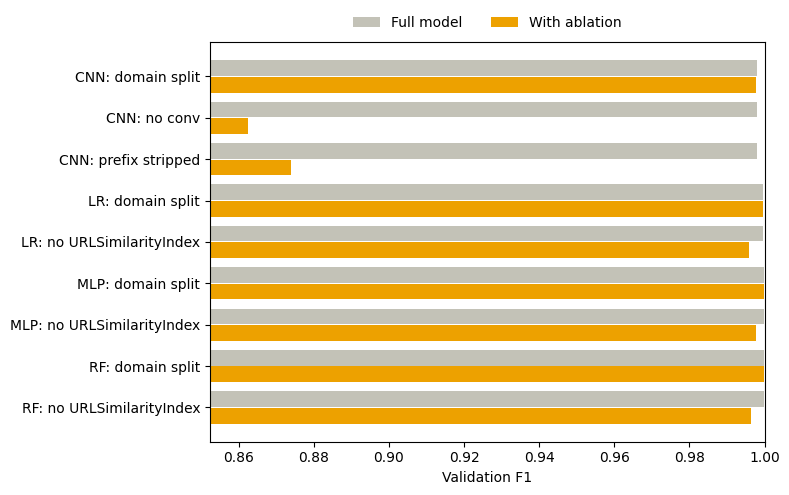

In [11]:
#ablation chart: validation F1, full model vs each ablation
# Each bar = that model's BEST validation F1 under that condition.
val = log[log['Split'] == 'val']
full = val[val['hp_experiment'].isin(['main', 'sweep'])].groupby('hp_family')['F1'].max()
abl = (val[val['hp_experiment'].str.startswith('ablation', na=False)]
       .sort_values('F1').groupby(['hp_family', 'hp_experiment']).tail(1))
abl = abl.assign(label=abl['hp_family'] + ': ' + abl['hp_experiment'].str.replace('ablation: ', ''),
                 full=abl['hp_family'].map(full))
abl = abl.sort_values(['hp_family', 'hp_experiment'])
fig, ax = plt.subplots(figsize=(8, 0.45 * len(abl) + 1))
y = np.arange(len(abl))
ax.barh(y - 0.2, abl['full'], 0.38, color='#c3c2b7', label='Full model')
ax.barh(y + 0.2, abl['F1'], 0.38, color='#eda100', label='With ablation')
ax.set_yticks(y, abl['label']); ax.invert_yaxis(); ax.set_xlabel('Validation F1')
lo = min(abl['F1'].min(), abl['full'].min()); ax.set_xlim(max(0, lo - 0.01), 1.0)
ax.legend(frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.tight_layout(); fig.savefig(FIG_DIR / 'ablations.png', dpi=200); plt.show()

In [13]:
#tables for the report
print(final[['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'False negatives', 'False positives']]
      .to_latex(index=False, float_format='%.4f'))

abl_table = abl.rename(columns={'label': 'Condition', 'full': 'Full-model F1', 'F1': 'Ablation F1'})
print(abl_table[['Condition', 'Full-model F1', 'Ablation F1', 'Recall', 'False negatives']]
      .to_latex(index=False, float_format='%.4f'))

\begin{tabular}{lrrrrrrr}
\toprule
Model & Accuracy & Precision & Recall & F1 & ROC-AUC & False negatives & False positives \\
\midrule
Logistic Regression & 0.9998 & 1.0000 & 0.9996 & 0.9998 & 0.9999 & 6 & 0 \\
Random Forest & 0.9999 & 1.0000 & 0.9999 & 0.9999 & 1.0000 & 2 & 0 \\
MLP & 0.9999 & 0.9999 & 0.9999 & 0.9999 & 0.9999 & 2 & 1 \\
Char-CNN & 0.9984 & 1.0000 & 0.9962 & 0.9981 & 0.9991 & 58 & 0 \\
\bottomrule
\end{tabular}

\begin{tabular}{lrrrr}
\toprule
Condition & Full-model F1 & Ablation F1 & Recall & False negatives \\
\midrule
CNN: domain split & 0.9979 & 0.9977 & 0.9955 & 68 \\
CNN: no conv & 0.9979 & 0.8624 & 0.7931 & 3133 \\
CNN: prefix stripped & 0.9979 & 0.8740 & 0.7988 & 3046 \\
LR: domain split & 0.9996 & 0.9996 & 0.9992 & 12 \\
LR: no URLSimilarityIndex & 0.9996 & 0.9958 & 0.9919 & 123 \\
MLP: domain split & 0.9998 & 0.9998 & 0.9997 & 5 \\
MLP: no URLSimilarityIndex & 0.9998 & 0.9978 & 0.9956 & 67 \\
RF: domain split & 0.9998 & 0.9998 & 0.9997 & 5 \\
RF: no URLSimi